# Activated-carbon catalyst: kinetic parameter refit

Refits the methane-pyrolysis rate law

$$r_0 = A \, \exp\!\left(-\frac{E_a}{R T}\right) P_{\mathrm{CH_4}}^{\,n}, \qquad n = 0.5$$

to initial-rate data digitized from Figure 6 of the reference paper, and compares the refitted model with the parameters reported in the paper.

**Workflow**
1. For each temperature, fit $k_p$ in $r_0 = k_p \, P_{\mathrm{CH_4}}^{\,n}$ (least squares through the origin).
2. Fit $\ln k_p$ vs. $1/T$ (Arrhenius) to obtain $A$ and $E_a$.
3. Predict $r_0$ with the refitted and paper parameters, then plot both against the data.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" / "ieee" styles)
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

R = 8.314462618  # Gas constant [J/(mol K)]

## 1. Experimental data and model settings

Values digitized (approximately) from Figure 6.
- $r_0$: initial rate [mmol / (g$_{cat}$ min)]
- $P_{\mathrm{CH_4}}$: methane partial pressure [atm]

In [2]:
P_CH4 = np.array([0.03, 0.10, 0.19, 0.43])  # [atm]

T_C = np.array([800.0, 850.0, 900.0, 950.0])  # [°C]
T_K = T_C + 273.15                             # [K]

# Initial rate r0 [mmol/(g_cat min)]
# rows    -> temperatures T_C
# columns -> pressures P_CH4
r0 = np.array([
    [0.035, 0.085, 0.145, 0.300],  # 800 °C
    [0.200, 0.470, 0.580, 0.760],  # 850 °C
    [0.620, 1.350, 1.800, 2.480],  # 900 °C
    [1.570, 2.450, 3.450, 4.300],  # 950 °C
])

# Reaction order in CH4 (fixed)
n = 0.5

# Parameters reported in the paper
A_paper = 1.0e10           # pre-exponential factor
Ea_paper_J_mol = 210000.0  # activation energy [J/mol]

## 2. Helper functions

In [3]:
def r_squared(y, y_pred):
    """Coefficient of determination R²."""
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan


def linear_regression(x, y):
    """Ordinary least squares: y = slope*x + intercept."""
    slope, intercept = np.polyfit(x, y, 1)
    y_pred = slope * x + intercept
    return slope, intercept, y_pred, r_squared(y, y_pred)


def fit_through_origin(x, y):
    """Least squares with zero intercept: y = k*x."""
    k = np.sum(x * y) / np.sum(x ** 2)
    y_pred = k * x
    return k, y_pred, r_squared(y, y_pred)


def rate_model(A, Ea_J_mol, T_K, P_CH4, n):
    """r0 = A exp(-Ea/(R T)) P^n, evaluated on a (T, P) grid."""
    k = A * np.exp(-Ea_J_mol / (R * T_K))         # shape (nT,)
    return k[:, np.newaxis] * P_CH4[np.newaxis, :] ** n  # shape (nT, nP)

## 3. Step 1: pressure fit at each temperature

$r_0 = k_p(T) \, P_{\mathrm{CH_4}}^{\,n}$, fitted through the origin.

In [4]:
x_pressure = P_CH4 ** n

kp = np.zeros(len(T_K))
r2_pressure = np.zeros(len(T_K))

for i, temperature in enumerate(T_C):
    kp[i], _, r2_pressure[i] = fit_through_origin(x_pressure, r0[i, :])
    print(f"T = {temperature:.0f} °C | kp = {kp[i]:.6g} | R² = {r2_pressure[i]:.6f}")

T = 800 °C | kp = 0.390492 | R² = 0.871128
T = 850 °C | kp = 1.24593 | R² = 0.935474
T = 900 °C | kp = 3.92685 | R² = 0.982444
T = 950 °C | kp = 7.16028 | R² = 0.903539


## 4. Step 2: Arrhenius fit

$\ln k_p = \ln A - \dfrac{E_a}{R} \cdot \dfrac{1}{T}$

In [5]:
def arrhenius_regression(T_K, kp, label):
    """Fit ln(kp) vs 1/T, print a summary and return the fitted parameters."""
    x = 1.0 / T_K
    y = np.log(kp)
    slope, intercept, y_pred, r2 = linear_regression(x, y)

    Ea_J_mol = -slope * R
    A = np.exp(intercept)

    print("=" * 75)
    print(label)
    print("=" * 75)
    print(f"Slope                 = {slope:.8e} K")
    print(f"Intercept ln(A)       = {intercept:.8f}")
    print(f"A                     = {A:.8e}")
    print(f"Ea                    = {Ea_J_mol / 1000.0:.4f} kJ/mol")
    print(f"R² Arrhenius          = {r2:.6f}")
    print()

    return {
        "slope": slope,
        "intercept": intercept,
        "A": A,
        "Ea_J_mol": Ea_J_mol,
        "Ea_kJ_mol": Ea_J_mol / 1000.0,
        "r_squared": r2,
        "x": x,
        "y": y,
        "y_pred": y_pred,
    }


arrhenius_fit = arrhenius_regression(T_K, kp, "ARRHENIUS FIT")

ARRHENIUS FIT
Slope                 = -2.60201420e+04 K
Intercept ln(A)       = 23.37058178
A                     = 1.41160994e+10
Ea                    = 216.3435 kJ/mol
R² Arrhenius          = 0.989457



## 5. Step 3: model predictions (refitted vs. paper)

In [6]:
# Model predictions at the measured temperatures (used for R²)
r0_refit = rate_model(arrhenius_fit["A"], arrhenius_fit["Ea_J_mol"], T_K, P_CH4, n)
r0_paper = rate_model(A_paper, Ea_paper_J_mol, T_K, P_CH4, n)

# Goodness of fit of each model against all data points
r2_refit = r_squared(r0.ravel(), r0_refit.ravel())
r2_paper = r_squared(r0.ravel(), r0_paper.ravel())
print(f"R² refitted model = {r2_refit:.4f}")
print(f"R² paper model    = {r2_paper:.4f}")

# Smooth model curves over the measured temperature range (for plotting)
T_fine_C = np.linspace(T_C.min(), T_C.max(), 200)
T_fine_K = T_fine_C + 273.15
r0_refit_fine = rate_model(arrhenius_fit["A"], arrhenius_fit["Ea_J_mol"], T_fine_K, P_CH4, n)
r0_paper_fine = rate_model(A_paper, Ea_paper_J_mol, T_fine_K, P_CH4, n)

R² refitted model = 0.9410
R² paper model    = 0.5789


## 6. Plot: data vs. refitted and paper models

In [7]:
# ---- Global figure style -------------------------------------------------
# Standard SciencePlots "science" + "ieee" look (3.3 x 2.5 in, 8 pt fonts),
# the same size as the tornado plots (figures S2-S4).
plt.style.use(["default", "science", "ieee"])

mpl.rcParams.update({
    "text.usetex": True,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# One color per CH4 partial pressure
COLORS = ["#5B6FFF", "#F0523A", "#00BF91", "#9B59B6"]

# Style per data source (color is added per pressure)
DATA_STYLE = dict(linestyle="None", marker="o", markersize=3.5, markerfacecolor="white",
                  markeredgewidth=0.8, zorder=4)  # open circles, edge takes the line color
REFIT_STYLE = dict(linestyle="-", linewidth=1.0, zorder=3)
PAPER_STYLE = dict(linestyle="--", linewidth=1.0, dashes=(4, 2), zorder=2)

# Shared, compact legend appearance (no frame)
LEGEND_KW = dict(
    loc="upper left",
    frameon=False,
    borderpad=0.0,
    labelspacing=0.25,
    handletextpad=0.5,
    borderaxespad=0.0,
)

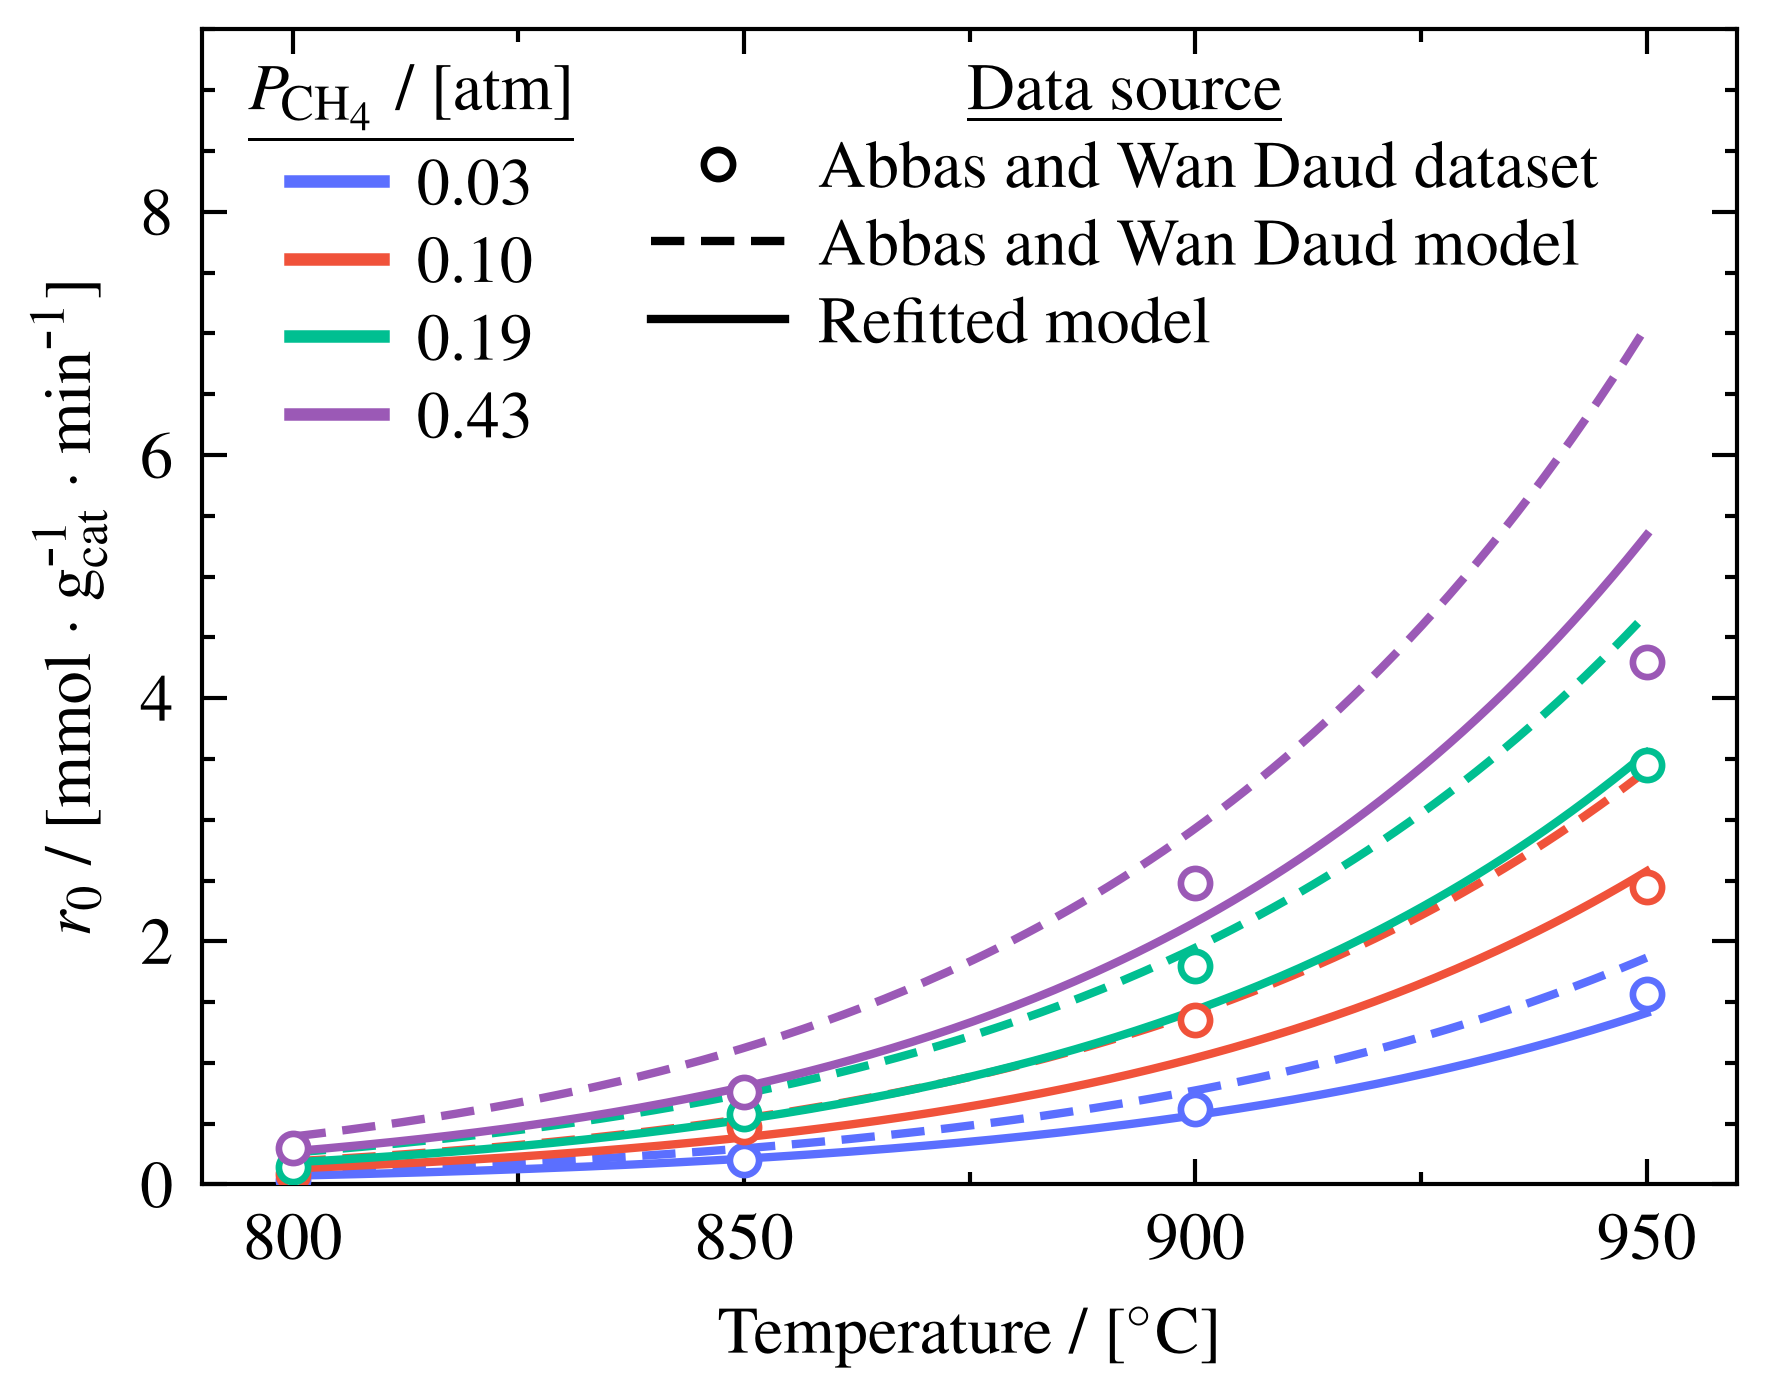

In [8]:
fig, ax = plt.subplots()

# ---- Data (markers) and continuous model curves ----------------------------
for j, color in enumerate(COLORS):
    ax.plot(T_C, r0[:, j], color=color, **DATA_STYLE)
    ax.plot(T_fine_C, r0_refit_fine[:, j], color=color, **REFIT_STYLE)
    ax.plot(T_fine_C, r0_paper_fine[:, j], color=color, **PAPER_STYLE)

# ---- Axes ------------------------------------------------------------------
ax.set_xlabel(r"Temperature / [$^\circ$C]")
ax.set_ylabel(
    r"$r_0$ / [$\mathrm{mmol}\,\cdot\,"
    r"\mathrm{g}_{\mathrm{cat}}^{\mbox{-}1}"
    r"\,\cdot\,\mathrm{min}^{\mbox{-}1}$]"
)

ax.set_xlim(T_C.min() - 10, T_C.max() + 10)
ax.set_ylim(0, 9.5)  # headroom so the legends clear the curves

ax.set_xticks(T_C)
ax.xaxis.set_minor_locator(MultipleLocator(25))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))

# ---- Legend 1: CH4 partial pressure (colors) -------------------------------
pressure_handles = [
    Line2D([0], [0], color=color, linewidth=1.5, label=rf"{pressure:.2f}")
    for pressure, color in zip(P_CH4, COLORS)
]
legend_pressure = ax.legend(
    handles=pressure_handles,
    title=r"\underline{$P_{\mathrm{CH_4}}$ / [atm]}",
    bbox_to_anchor=(0.03, 0.97),
    handlelength=1.4,
    **LEGEND_KW,
)
ax.add_artist(legend_pressure)  # keep it when the second legend is added

# ---- Legend 2: data source -------------------------------------------------
# Placed directly to the right of the pressure legend, top-aligned.
fig.canvas.draw()
p_box = legend_pressure.get_window_extent().transformed(ax.transAxes.inverted())

type_handles = [
    Line2D([0], [0], color="black", label="Abbas and Wan Daud dataset", **DATA_STYLE),
    Line2D([0], [0], color="black", label="Abbas and Wan Daud model", **PAPER_STYLE),
    Line2D([0], [0], color="black", label="Refitted model", **REFIT_STYLE),
]
legend_type = ax.legend(
    handles=type_handles,
    title=r"\underline{Data source}",
    bbox_to_anchor=(p_box.x1 + 0.05, p_box.y1),
    handlelength=2.0,
    **LEGEND_KW,
)

# ---- Save ----------------------------------------------------------------
fig.savefig(Path("figure-s1.pdf"), format="pdf", dpi=600, bbox_inches="tight")
plt.show()